# News popularity: six hours to 48 hours

Predict an article's **Facebook URL shares at 48 hours** from its first six hours of observations, title/headline, source and topic. One article is one example. This is an interview-sized regression project, not a pageview or seven-day forecast.

**Executed result.** Metadata boosting was selected on May validation. On 3,234 held-out articles it achieved **RMSLE 0.737**, **MAE 76.8 shares** and **RMSE 369.7 shares**, a **32.9% RMSLE reduction** versus persistence. Text improved Ridge's May RMSLE by 0.0116, but boosting narrowly won the selection metric. These findings apply to articles observable within six hours; missing early histories and unverifiable timestamp details limit the claim.

## 1. Question and evaluation

**Decision:** at publication time + 6 hours, forecast `TS144`. Inputs stop at `TS18`. The main score is RMSLE; MAE and RMSE show errors in shares. A fixed chronological test estimates performance on later articles from the same collection process.

**Recovered working rules.** The stock-project chat explicitly requested minimalist code, `ColumnTransformer` inside `Pipeline`, and training-only preprocessing. The stock notebook uses chronological splits and label-boundary checks. The SIG notebook distinguishes available information from reference-only signals, separates retrospective strategy selection from untouched evaluation, and reconciles outputs. Your supplied instructions add compact checks, separate dataset inspection and captions below plots. These are recovered from accessible files/chat; complete historical SIG conversations were not recovered.

**Presentation route:** target → data limitations → chronological split → two EDA findings → baselines and ablation → test errors → limitations. The notebook retains the supporting checks.

### Source contract and assumptions

| Item | Verified meaning / working rule |
|---|---|
| Dataset | UCI **News Popularity in Multiple Social Media Platforms**, ID 432; not Online News Popularity |
| `TS1` / `TS18` / `TS144` | Publication-age slices 0–20 minutes / 340–360 minutes / 48 hours |
| Facebook measure | Repeated snapshots of the number of shares of each URL, not interval counts, pageviews or unique people |
| `-1` | Measurement unavailable; never interpret as a negative share count or zero |
| Late discovery | Articles can enter aggregators late, leaving initial slices unavailable |
| Metadata | Paper says title, headline, source and publication date are collected before querying social feedback; topic is the collection query |
| Timing limits | No per-slice request timestamps, ingestion timestamps or timezone are supplied. Use documented age slices and naive source timestamps; exact real-time availability cannot be independently reconstructed |
| Metadata limits | Use the documented collected text for articles observed by six hours; no revision history proves it was never updated. A live system needs versioned snapshots |
| Exclusions | IDs, supplied sentiment scores, final platform totals and `TS19`–`TS143` are not predictors |

Sources: [UCI dataset and license](https://archive.ics.uci.edu/dataset/432/news+popularity+in+multiple+social+media+platforms), archive `readme.txt`, and [Moniz & Torgo, 2018, Sections 3–4](https://arxiv.org/html/1801.07055v1). The UCI page's generic “no missing values” flag conflicts with the paper and files; the explicit sentinel convention controls this analysis.

### Design fixed before model evaluation

- Training: 10 November 2015 to May 2016 boundary; expanding validation folds start 1 March and 1 April.
- Model-selection validation: May 2016. Final test: 1 June onward.
- A training label must be available **before the next period's publication start**. Require `publication + 48h + 20min < boundary`. This is more conservative than using the next article's six-hour prediction time. The additional 20 minutes is a polling allowance, not verified latency.
- Final cohort ends when the same label-availability clock reaches 7 July 00:00, conservatively before the last documented collection day ends.
- Require at least one valid early measurement and an observed nonnegative target. Report exclusions; this forecasts observable articles, not all published news.
- Pick hyperparameters on training-only chronological folds, then choose a family on May RMSLE. Refit the frozen choice on all eligible pre-June rows, then open the test once. No random validation or test-guided revisions.

### Setup

Run from this directory. The first run downloads the public archive; later runs verify its checksum and reuse it. Only pandas, NumPy, Matplotlib and scikit-learn are needed for analysis, plus Jupyter tooling.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
DATA = Path('data')
RESULTS = Path('results')
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GOLD = '#356B96', '#B17C28'
run_started = time.perf_counter()

## 2. Acquire and inspect the files

The checksum pins the actual archive used here. A changed download raises an error instead of silently changing the experiment. Extract named files only; the archive also contains other platforms and unrelated desktop/R history files.

In [2]:
URL = ('https://archive.ics.uci.edu/static/public/432/'
       'news%2Bpopularity%2Bin%2Bmultiple%2Bsocial%2Bmedia%2Bplatforms.zip')
EXPECTED_SHA256 = '5b8a7a10c8942a611da33d0fd4df7cb100f9f1b47d49a73fd13b142624f66f81'
archive = DATA / 'uci_news_popularity.zip'
if not archive.exists():
    temporary = archive.with_suffix('.download')
    with urllib.request.urlopen(URL, timeout=90) as response:
        temporary.write_bytes(response.read())
    temporary.replace(archive)
archive_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
assert archive_hash == EXPECTED_SHA256, 'Archive changed: inspect before continuing.'

topics = ['Economy', 'Microsoft', 'Obama', 'Palestine']
required_files = ['readme.txt', 'Auxiliary.R', 'Data/News_Final.csv']
for topic in topics:
    required_files.append(f'Data/Facebook_{topic}.csv')
with zipfile.ZipFile(archive) as bundle:
    for name in required_files:
        destination = DATA / name
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(bundle.read(name))
print('Archive verified:', archive_hash)
print('Named files extracted:', len(required_files))

Archive verified: 5b8a7a10c8942a611da33d0fd4df7cb100f9f1b47d49a73fd13b142624f66f81
Named files extracted: 7


### Metadata schema

Inspect metadata separately. The original final popularity columns are retained only long enough to audit the training join; they never enter the feature frame.

In [3]:
news = pd.read_csv(DATA / 'Data/News_Final.csv')
metadata_schema = pd.DataFrame({'dtype': news.dtypes.astype(str),
                                'missing': news.isna().sum()})
print('Metadata rows and columns:', news.shape)
display(metadata_schema)

Metadata rows and columns: (93239, 11)


,dtype,missing
IDLink,float64,0
Title,str,0
Headline,str,15
Source,str,279
Topic,str,0
PublishDate,str,0
SentimentTitle,float64,0
SentimentHeadline,float64,0
Facebook,int64,0
GooglePlus,int64,0


In [4]:
display(news[['IDLink', 'Title', 'Source', 'Topic', 'PublishDate']].head(3))

,IDLink,Title,Source,Topic,PublishDate
0,99248.0,Obama Lays Wreath at Arlington National Cemetery,USA TODAY,obama,2002-04-02 00:00:00
1,10423.0,A Look at the Health of the Chinese Economy,Bloomberg,economy,2008-09-20 00:00:00
2,18828.0,Nouriel Roubini: Global Economy Not Back to 2008,Bloomberg,economy,2012-01-28 00:00:00


### Facebook files

Check the complete expected schema in each topic file. Concatenation stacks articles; joining different platforms would instead repeat or widen article records. Other platforms are outside this prediction task.

In [5]:
all_slices = [f'TS{i}' for i in range(1, 145)]
early_slices = [f'TS{i}' for i in range(1, 19)]
facebook_parts = []
file_checks = []
for topic in topics:
    frame = pd.read_csv(DATA / f'Data/Facebook_{topic}.csv').copy()
    assert frame.columns.tolist() == ['IDLink'] + all_slices
    assert frame['IDLink'].is_unique
    assert frame[all_slices].ge(-1).all().all()
    assert frame[all_slices].notna().all().all()
    file_checks.append({'file': f'Facebook_{topic}.csv', 'rows': len(frame),
                        'columns': frame.shape[1], 'duplicate_ids': 0})
    frame['file_topic'] = topic.lower()
    facebook_parts.append(frame)
facebook = pd.concat(facebook_parts, ignore_index=True)
assert facebook['IDLink'].is_unique
display(pd.DataFrame(file_checks))

,file,rows,columns,duplicate_ids
0,Facebook_Economy.csv,29928,145,0
1,Facebook_Microsoft.csv,18531,145,0
2,Facebook_Obama.csv,27015,145,0
3,Facebook_Palestine.csv,7687,145,0


### Join and identity checks

Remove identical metadata rows, then require a one-to-one ID join. Conflicting metadata or repeated Facebook IDs fail explicitly. Do not aggregate duplicate rows by their target. Audit unmatched records before taking the matched cohort.

In [6]:
exact_metadata_duplicates = int(news.duplicated().sum())
news = news.drop_duplicates().copy()
assert news['IDLink'].is_unique, 'Conflicting metadata for an article ID.'
assert news['IDLink'].mod(1).eq(0).all()
news['IDLink'] = news['IDLink'].astype('int64')
news['PublishDate'] = pd.to_datetime(news['PublishDate'], errors='coerce')
join_audit = news[['IDLink']].merge(facebook[['IDLink']], on='IDLink',
                                   how='outer', validate='one_to_one', indicator=True)
print('Identical metadata rows removed:', exact_metadata_duplicates)
display(join_audit['_merge'].value_counts().rename('articles').to_frame())

Identical metadata rows removed: 4


,articles
_merge,
both,83161
left_only,10074
right_only,0


In [7]:
joined = news.merge(facebook, on='IDLink', how='inner', validate='one_to_one')
assert len(joined) == len(facebook)
assert joined['Topic'].eq(joined['file_topic']).all()
print('Joined articles:', len(joined))
print('Timestamp parse failures:', joined['PublishDate'].isna().sum())
print('Raw publication range:', news['PublishDate'].min(), 'to', news['PublishDate'].max())

Joined articles: 83161
Timestamp parse failures: 0
Raw publication range: 2002-04-02 00:00:00 to 2016-07-07 16:16:11


### Content duplicates

The paper deduplicated title/headline/source combinations. We additionally keep the earliest **normalized title + headline** across sources and topics, so syndicated exact text cannot cross splits. This rule uses only content, time and an ID tie-break, never a target. The first occurrence is retained even if later copies have better data. Missing text is not treated as shared content. Different text versions and near duplicates remain a limitation.

In [8]:
exact_content_duplicates = int(joined.duplicated(['Title', 'Headline']).sum())
title_key = joined['Title'].fillna('').str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
headline_key = joined['Headline'].fillna('').str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
joined['content_key'] = title_key + '\n' + headline_key
empty_content = title_key.eq('') & headline_key.eq('')
joined.loc[empty_content, 'content_key'] = joined.loc[empty_content, 'IDLink'].astype(str)
joined = joined.sort_values(['PublishDate', 'IDLink'])
article_data = joined.drop_duplicates('content_key', keep='first').copy()
print('Repeated exact title/headline rows:', exact_content_duplicates)
print('Repeated normalized content rows removed:', len(joined) - len(article_data))
assert article_data['IDLink'].is_unique
assert article_data['content_key'].is_unique

Repeated exact title/headline rows: 2738
Repeated normalized content rows removed: 2967


## 3. Split before learning

Date restrictions, sentinel decoding and content identity are fixed data rules, not fitted preprocessing. Structural checks may inspect all rows; feature–target relationships and distributional EDA below use training only. Missing targets are unscorable, not zero. We retain partially observed six-hour histories and let each fitted pipeline impute its own medians.

In [9]:
COLLECTION_START = pd.Timestamp('2015-11-10')
VALID_START = pd.Timestamp('2016-05-01')
TEST_START = pd.Timestamp('2016-06-01')
COLLECTION_END = pd.Timestamp('2016-07-07')
LABEL_DELAY = pd.Timedelta(hours=48, minutes=20)
article_data['label_available_at'] = article_data['PublishDate'] + LABEL_DELAY
article_data['prediction_time'] = article_data['PublishDate'] + pd.Timedelta(hours=6)
article_data[early_slices] = article_data[early_slices].replace(-1, np.nan)
article_data['target'] = article_data['TS144'].where(article_data['TS144'].ge(0))

in_window = (article_data['PublishDate'].ge(COLLECTION_START)
             & article_data['label_available_at'].lt(COLLECTION_END))
has_early = article_data[early_slices].notna().any(axis=1)
has_target = article_data['target'].notna()
cohort_audit = pd.Series({
    'unique normalized articles': len(article_data),
    'outside conservative collection window': int((~in_window).sum()),
    'in window, no early observation': int((in_window & ~has_early).sum()),
    'in window + early observation, missing target': int((in_window & has_early & ~has_target).sum()),
    'eligible labeled articles': int((in_window & has_early & has_target).sum())})
display(cohort_audit.rename('articles').to_frame())

,articles
unique normalized articles,80194
outside conservative collection window,559
"in window, no early observation",39182
"in window + early observation, missing target",0
eligible labeled articles,40453


In [10]:
eligible = article_data.loc[in_window & has_early & has_target].copy()
train = eligible.loc[eligible['label_available_at'].lt(VALID_START)].copy()
valid = eligible.loc[eligible['PublishDate'].ge(VALID_START)
                     & eligible['label_available_at'].lt(TEST_START)].copy()
test = eligible.loc[eligible['PublishDate'].ge(TEST_START)].copy()
development = eligible.loc[eligible['label_available_at'].lt(TEST_START)].copy()
split_rows = []
for name, split in [('train', train), ('validation', valid), ('test', test)]:
    assert split['PublishDate'].is_monotonic_increasing
    split_rows.append({'split': name, 'articles': len(split),
                       'first_publication': split['PublishDate'].min(),
                       'last_publication': split['PublishDate'].max(),
                       'last_label_available': split['label_available_at'].max()})
display(pd.DataFrame(split_rows).set_index('split'))

,articles,first_publication,last_publication,last_label_available
split,,,,
train,32082,2015-11-10 00:00:09,2016-04-28 23:35:13,2016-04-30 23:55:13
validation,4414,2016-05-01 00:05:12,2016-05-29 23:07:31,2016-05-31 23:27:31
test,3234,2016-06-01 00:00:08,2016-07-04 22:48:19,2016-07-06 23:08:19


In [11]:
assert train['label_available_at'].max() < VALID_START
assert valid['label_available_at'].max() < TEST_START
assert development['label_available_at'].max() < TEST_START
assert test['label_available_at'].max() < COLLECTION_END
assert train['prediction_time'].lt(VALID_START).all()
for key in ['IDLink', 'content_key']:
    assert set(train[key]).isdisjoint(valid[key])
    assert set(train[key]).isdisjoint(test[key])
    assert set(valid[key]).isdisjoint(test[key])
boundary_rows = len(eligible) - len(train) - len(valid) - len(test)
print('Articles omitted around train/validation/test boundaries:', boundary_rows)
print('Split identity, chronology and label-availability checks passed.')

Articles omitted around train/validation/test boundaries: 723
Split identity, chronology and label-availability checks passed.


Final refitting may recover the gap immediately before May because its labels are then available by June. The gap immediately before June remains excluded. Cohort eligibility and split sizes are the only test information used before the final evaluation; no test target magnitudes are summarized yet.

### Training measurement checks

Share snapshots are cumulative levels according to the collection description. Differences are changes in reported shares, not guaranteed new human sharing events. Check adjacent observed slices before deriving growth. If a future version contains a decrease, retain it as a signed change with a flag rather than silently clipping it or imposing a cumulative maximum.

In [12]:
train_early = train[early_slices]
adjacent_changes = train_early.diff(axis=1)
observed_changes = adjacent_changes.stack()
successive_observed_changes = train_early.ffill(axis=1).diff(axis=1).where(train_early.notna())
measurement_checks = pd.Series({
    'training articles': len(train),
    'articles with an early decrease': adjacent_changes.lt(0).any(axis=1).sum(),
    'negative adjacent observed changes': observed_changes.lt(0).sum(),
    'decreases between successive available observations': successive_observed_changes.lt(0).sum().sum(),
    'target below latest early level': train['target'].lt(train_early.ffill(axis=1).iloc[:, -1]).sum(),
    'metadata Facebook differs from TS144': train['Facebook'].ne(train['TS144']).sum(),
    'articles with partial early history': train_early.isna().any(axis=1).sum()})
display(measurement_checks.rename('count').to_frame())

,count
training articles,32082
articles with an early decrease,0
negative adjacent observed changes,0
decreases between successive available observations,0
target below latest early level,0
metadata Facebook differs from TS144,0
articles with partial early history,24695


## 4. Training EDA

Use no future slices in predictors or correlations. Zero remains a real observed count. Plots summarize the retained training population, not the entire news ecosystem.

### Availability in the first six hours

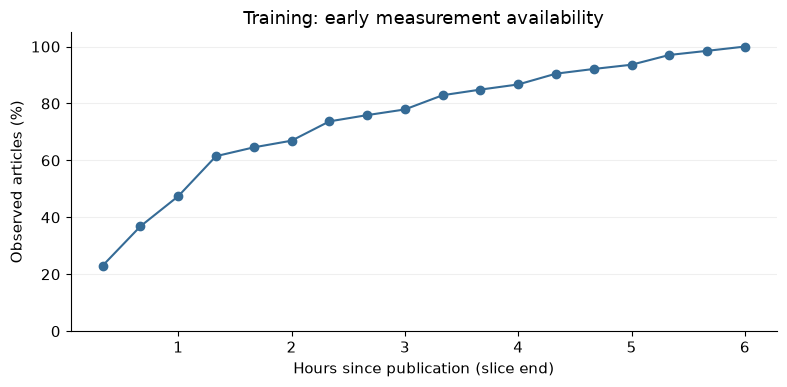

Training coverage rises from **23.0%** at TS1 to **100.0%** at TS18. Missing early slices are not zero activity.

In [13]:
availability = train_early.notna().mean()
fig, ax = plt.subplots()
ax.plot(np.arange(1, 19) / 3, availability * 100, marker='o', color=BLUE)
ax.set(xlabel='Hours since publication (slice end)', ylabel='Observed articles (%)',
       title='Training: early measurement availability', ylim=(0, 105))
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()
display(Markdown(f'Training coverage rises from **{availability.iloc[0]:.1%}** at TS1 to '
                 f'**{availability.iloc[-1]:.1%}** at TS18. Missing early slices are not zero activity.'))

### Target distribution

In [14]:
display(train['target'].describe(percentiles=[.5, .9, .99]).round(1).to_frame('48-hour shares'))

,48-hour shares
count,32082.0
mean,158.7
std,786.4
min,0.0
50%,11.0
90%,278.0
99%,2769.1
max,49211.0


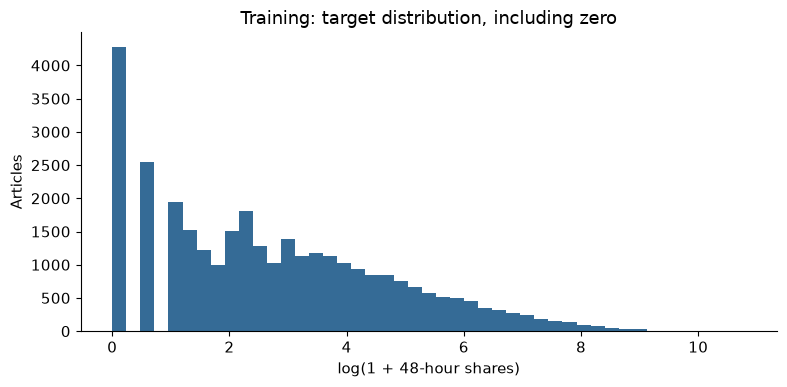

**13.4%** of training labels are zero; the median is **11** shares and the 99th percentile is **2,769**. Log-scale loss limits domination by viral articles.

In [15]:
fig, ax = plt.subplots()
ax.hist(np.log1p(train['target']), bins=45, color=BLUE)
ax.set(xlabel='log(1 + 48-hour shares)', ylabel='Articles',
       title='Training: target distribution, including zero')
fig.tight_layout()
plt.show()
display(Markdown(f'**{train["target"].eq(0).mean():.1%}** of training labels are zero; '
                 f'the median is **{train["target"].median():,.0f}** shares and the 99th percentile is '
                 f'**{train["target"].quantile(.99):,.0f}**. Log-scale loss limits domination by viral articles.'))

### Six-hour level and later popularity

The latest observed value can be older than TS18. Carrying it forward **within the same article** uses known history; an age feature records its staleness. This does not fill from future slices.

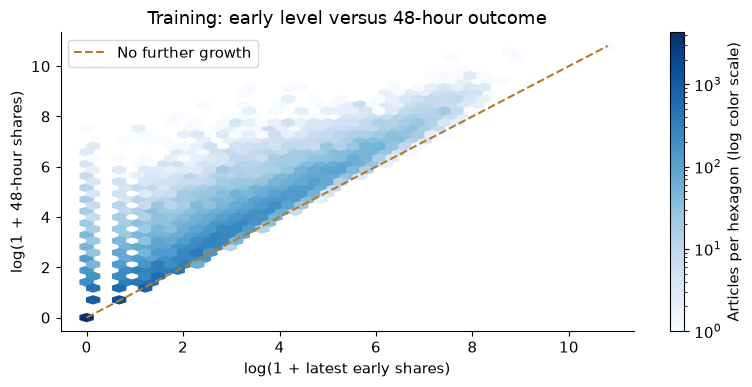

**74.3%** of training articles grow after their last early observation. The association supports a strong latest-level baseline; it is not a causal result.

In [16]:
latest_train = train_early.ffill(axis=1).iloc[:, -1]
fig, ax = plt.subplots()
density = ax.hexbin(np.log1p(latest_train), np.log1p(train['target']),
                    gridsize=40, mincnt=1, bins='log', cmap='Blues')
limit = float(np.log1p(train['target']).max())
ax.plot([0, limit], [0, limit], '--', color=GOLD, label='No further growth')
ax.set(xlabel='log(1 + latest early shares)', ylabel='log(1 + 48-hour shares)',
       title='Training: early level versus 48-hour outcome')
ax.legend()
fig.colorbar(density, ax=ax, label='Articles per hexagon (log color scale)')
fig.tight_layout()
plt.show()
display(Markdown(f'**{train["target"].gt(latest_train).mean():.1%}** of training articles grow after '
                 'their last early observation. The association supports a strong latest-level baseline; it is not a causal result.'))

### Time and topic coverage

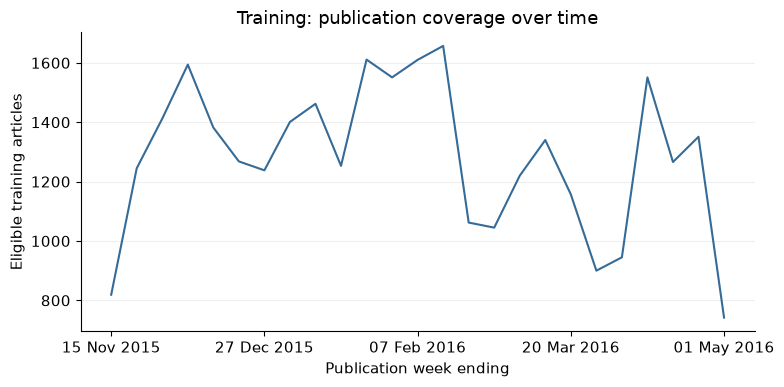

Eligible training volume ranges from **742** to **1,657** articles per displayed week. Edge weeks are partial; volume reflects collection and eligibility as well as publishing activity.

In [17]:
weekly_articles = train.set_index('PublishDate').resample('W')['IDLink'].count()
fig, ax = plt.subplots()
ax.plot(weekly_articles.index, weekly_articles, color=BLUE)
ax.set(xlabel='Publication week ending', ylabel='Eligible training articles',
       title='Training: publication coverage over time')
tick_positions = np.linspace(0, len(weekly_articles) - 1, 5, dtype=int)
ax.set_xticks(weekly_articles.index[tick_positions])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
ax.grid(axis='y', alpha=.2)
fig.autofmt_xdate(rotation=0, ha='center')
fig.tight_layout()
plt.show()
display(Markdown(f'Eligible training volume ranges from **{weekly_articles.min():,}** to '
                 f'**{weekly_articles.max():,}** articles per displayed week. Edge weeks are partial; '
                 'volume reflects collection and eligibility as well as publishing activity.'))

In [18]:
topic_summary = train.groupby('Topic')['target'].agg(articles='size', median='median', mean='mean')
display(topic_summary.round(1))

,articles,median,mean
Topic,,,
economy,11634,5.0,55.4
microsoft,6379,6.0,40.0
obama,10883,56.0,367.2
palestine,3186,5.0,61.8


Topic counts and typical popularity differ, motivating a metadata ablation. Source/topic effects can also reflect coverage, audience and events; they are not causal explanations.

## 5. Deterministic six-hour features

All calculations below operate on one article's first 18 slices. No cross-row statistics are learned here. Keep missing endpoints missing; do not interpolate across unobserved slices. A fixed signed `log1p` compresses growth features without erasing negative changes.

| Feature group | Definition |
|---|---|
| Levels | `log1p` of each early slice, latest/first/max/mean/standard deviation |
| Growth | Adjacent observed increments; early TS1→TS9 and recent TS10→TS18 rates, each over 8/3 hours; rate difference |
| Slope | First-to-last observed log-level change divided by elapsed hours |
| Availability/activity | Missing fraction, observed zero fraction, last-observation age, decrease count |
| Metadata | Source/topic indicators; sine/cosine of publication hour and weekday (source timezone unspecified) |
| Text | Title/headline lengths and word counts; combined TF-IDF with at most 5,000 terms |

In [19]:
def signed_log(values):
    return np.sign(values) * np.log1p(np.abs(values))

def trajectory_features(frame):
    history = frame[early_slices]
    observed = history.notna()
    slice_numbers = np.arange(1, 19)
    first_slice = observed.mul(slice_numbers).where(observed).min(axis=1)
    last_slice = observed.mul(slice_numbers).max(axis=1)
    first = history.bfill(axis=1).iloc[:, 0]
    latest = history.ffill(axis=1).iloc[:, -1]
    changes = history.diff(axis=1)
    early_rate = (history['TS9'] - history['TS1']) / (8 / 3)
    recent_rate = (history['TS18'] - history['TS10']) / (8 / 3)
    elapsed_hours = ((last_slice - first_slice) / 3).replace(0, np.nan)
    features = np.log1p(history).add_prefix('log_')
    features['log_latest'] = np.log1p(latest)
    features['log_first'] = np.log1p(first)
    features['log_max'] = np.log1p(history.max(axis=1))
    features['log_mean'] = np.log1p(history.mean(axis=1))
    features['log_std'] = np.log1p(history.std(axis=1))
    features['log_increment_mean'] = signed_log(changes.mean(axis=1))
    features['log_increment_std'] = np.log1p(changes.std(axis=1))
    features['log_early_rate'] = signed_log(early_rate)
    features['log_recent_rate'] = signed_log(recent_rate)
    features['log_acceleration'] = signed_log(recent_rate - early_rate)
    features['log_slope_per_hour'] = (np.log1p(latest) - np.log1p(first)) / elapsed_hours
    features['missing_fraction'] = 1 - observed.mean(axis=1)
    features['zero_fraction'] = history.eq(0).sum(axis=1) / observed.sum(axis=1)
    features['latest_age_hours'] = (18 - last_slice) / 3
    features['decrease_count'] = changes.lt(0).sum(axis=1)
    return features

In [20]:
def make_features(frame):
    features = trajectory_features(frame)
    publication = frame['PublishDate']
    hour = publication.dt.hour + publication.dt.minute / 60
    weekday = publication.dt.dayofweek
    features['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    features['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    features['weekday_sin'] = np.sin(2 * np.pi * weekday / 7)
    features['weekday_cos'] = np.cos(2 * np.pi * weekday / 7)
    features['Source'] = frame['Source'].fillna('__missing__').astype(str)
    features['Topic'] = frame['Topic'].fillna('__missing__').astype(str)
    title = frame['Title'].fillna('')
    headline = frame['Headline'].fillna('')
    features['title_chars'] = title.str.len()
    features['headline_chars'] = headline.str.len()
    features['title_words'] = title.str.split().str.len()
    features['headline_words'] = headline.str.split().str.len()
    features['text'] = (title + ' ' + headline).str.strip()
    return features

X_train = make_features(train)
y_train = train['target']
X_valid = make_features(valid)
y_valid = valid['target']
trajectory_columns = trajectory_features(train).columns.tolist()
calendar_columns = ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos']
text_length_columns = ['title_chars', 'headline_chars', 'title_words', 'headline_words']
category_columns = ['Source', 'Topic']
print('Training feature rows and columns:', X_train.shape)

Training feature rows and columns: (32082, 44)


### Feature availability and row-level checks

The feature builder receives only an explicit allowlist. Changing an article's target or later slices must not affect its inputs; calculating one row alone must match calculating it in a batch.

In [21]:
raw_allowed = early_slices + ['Title', 'Headline', 'Source', 'Topic', 'PublishDate']
pd.testing.assert_frame_equal(make_features(train[raw_allowed]), X_train)
np.testing.assert_allclose(np.expm1(X_train['log_latest']), train_early.ffill(axis=1).iloc[:, -1])
probe = train.head(3).copy()
probe['TS144'] = 987654321
probe['target'] = 987654321
probe['Facebook'] = 987654321
probe['TS19'] = 987654321
pd.testing.assert_frame_equal(make_features(probe), X_train.head(3))
pd.testing.assert_frame_equal(make_features(train.iloc[[0]]), X_train.iloc[[0]])
assert X_train.columns.is_unique
assert not {'IDLink', 'target', 'Facebook', 'GooglePlus', 'LinkedIn', 'TS144'} & set(X_train.columns)
assert not np.isinf(X_train.select_dtypes(include='number').to_numpy()).any()
print('Allowed inputs, future-field independence and row-level feature checks passed.')

Allowed inputs, future-field independence and row-level feature checks passed.


### Numeric correlations only

Use a small, explicit numeric selection from training. The target is clearly labeled; identifiers, categories and unavailable measurements are excluded. Correlation is descriptive and does not choose features.

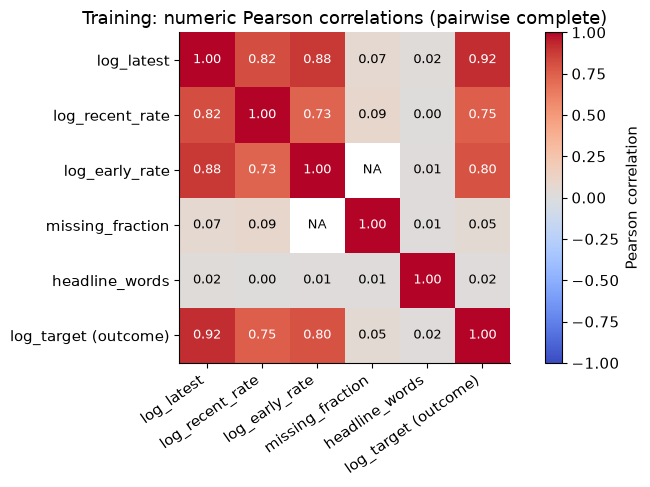

Latest early log-popularity correlates **0.92** with the log target in training. NA denotes an undefined correlation from zero variance within a paired sample; nominal categories are excluded.

In [22]:
correlation_frame = X_train[['log_latest', 'log_recent_rate', 'log_early_rate',
                              'missing_fraction', 'headline_words']].copy()
correlation_frame['log_target (outcome)'] = np.log1p(y_train)
correlations = correlation_frame.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
for (row, column), value in np.ndenumerate(correlations.to_numpy()):
    label = 'NA' if np.isnan(value) else f'{value:.2f}'
    color = 'white' if abs(value) > .65 else 'black'
    ax.text(column, row, label, ha='center', va='center', fontsize=9, color=color)
ax.set_xticks(range(len(correlations)), correlations.columns, rotation=35, ha='right')
ax.set_yticks(range(len(correlations)), correlations.columns)
ax.set_title('Training: numeric Pearson correlations (pairwise complete)')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
plt.show()
display(Markdown(f'Latest early log-popularity correlates **{correlations.loc["log_latest", "log_target (outcome)"]:.2f}** '
                 'with the log target in training. NA denotes an undefined correlation from zero variance '
                 'within a paired sample; nominal categories are excluded.'))

## 6. Models and training-only selection

**RMSLE** = square root of mean squared `log1p` prediction error. It emphasizes proportional discrepancies while allowing zero. **MAE** is average absolute error in shares. **RMSE** penalizes large share-count misses more heavily. Avoid MAPE because zero targets are common.

Fit squared-error models to `log1p(target)` using `TransformedTargetRegressor`; inverse-transform with `expm1` and floor negative predictions at zero. This estimates a conditional mean on the log scale, **not** an unbiased conditional mean of shares. No post-test smearing correction or clipping threshold is fitted.

Models progress from a training log-mean constant and latest-observation persistence to one-variable Ridge, regularized multi-feature Ridge, and histogram gradient boosting. The matched Ridge ablation uses trajectory only, then metadata, then text lengths and TF-IDF. The nonlinear model uses trajectory + metadata for modest compute.

### Preprocessing inside the model

Medians, scaling, category frequencies and vocabulary are learned in `fit`. Each cross-validation fold fits a fresh complete pipeline. We do not use target encoding, PCA, feature selection, winsorization or missingness-based column removal. Constant missing text/category replacements are fixed rules, not learned statistics.

In [23]:
def make_model(numeric_columns, estimator, metadata=False, text=False, dense=False):
    numeric_steps = [('impute', SimpleImputer(strategy='median', add_indicator=True,
                                              keep_empty_features=True))]
    if not dense:
        numeric_steps.append(('scale', StandardScaler()))
    transformers = [('numeric', Pipeline(numeric_steps), numeric_columns)]
    if metadata:
        encoder = OneHotEncoder(handle_unknown='infrequent_if_exist',
                                min_frequency=20, max_categories=40,
                                sparse_output=not dense)
        transformers.append(('category', encoder, category_columns))
    if text:
        vectorizer = TfidfVectorizer(max_features=5000, min_df=5,
                                     ngram_range=(1, 2), sublinear_tf=True,
                                     strip_accents='unicode')
        transformers.append(('text', vectorizer, 'text'))
    preprocessing = ColumnTransformer(transformers, remainder='drop',
                                      sparse_threshold=0 if dense else 1.0)
    pipeline = Pipeline([('preprocess', preprocessing), ('model', estimator)])
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p,
                                       inverse_func=np.expm1)

def predict_nonnegative(model, features):
    predictions = np.maximum(model.predict(features), 0)
    assert np.isfinite(predictions).all()
    return predictions

def metrics(actual, predicted):
    return {'RMSLE': np.sqrt(mean_squared_error(np.log1p(actual), np.log1p(predicted))),
            'MAE_shares': mean_absolute_error(actual, predicted),
            'RMSE_shares': np.sqrt(mean_squared_error(actual, predicted))}

### Two expanding chronological folds within training

March and April are validation windows inside the outer training period. Their fitting rows must have mature labels before the fold starts. The full pipeline is refitted by `GridSearchCV`, rather than preprocessing once and cross-validating the transformed matrix. Fold mean RMSLE gives the two periods equal weight.

In [24]:
folds = []
fold_audit = []
for fold_start, fold_end in [('2016-03-01', '2016-04-01'), ('2016-04-01', '2016-05-01')]:
    fit_mask = train['label_available_at'].lt(fold_start)
    score_mask = train['PublishDate'].ge(fold_start) & train['PublishDate'].lt(fold_end)
    fit_rows = np.flatnonzero(fit_mask)
    score_rows = np.flatnonzero(score_mask)
    assert len(fit_rows) > 0 and len(score_rows) > 0
    assert train.iloc[fit_rows]['label_available_at'].max() < pd.Timestamp(fold_start)
    assert set(train.iloc[fit_rows]['content_key']).isdisjoint(train.iloc[score_rows]['content_key'])
    folds.append((fit_rows, score_rows))
    fold_audit.append({'validation_start': fold_start, 'fit_articles': len(fit_rows),
                       'score_articles': len(score_rows),
                       'latest_fit_label': train.iloc[fit_rows]['label_available_at'].max()})
display(pd.DataFrame(fold_audit))

,validation_start,fit_articles,score_articles,latest_fit_label
0,2016-03-01,21512,4983,2016-02-29 23:31:10
1,2016-04-01,26479,5263,2016-03-31 23:55:09


In [25]:
def negative_rmsle(estimator, features, target):
    predicted = predict_nonnegative(estimator, features)
    return -metrics(target, predicted)['RMSLE']

ridge_options = {'regressor__model__alpha': [1.0, 10.0, 100.0]}
model_specs = {
    'Six-hour Ridge': (make_model(['log_latest'], Ridge(solver='lsqr')), {}),
    'Trajectory Ridge': (make_model(trajectory_columns, Ridge(solver='lsqr')), ridge_options),
    'Metadata Ridge': (make_model(trajectory_columns + calendar_columns,
                                  Ridge(solver='lsqr'), metadata=True), ridge_options),
    'Text Ridge': (make_model(trajectory_columns + calendar_columns + text_length_columns,
                              Ridge(solver='lsqr'), metadata=True, text=True), ridge_options),
    'Metadata boosting': (make_model(trajectory_columns + calendar_columns,
        HistGradientBoostingRegressor(max_iter=150, learning_rate=.06, min_samples_leaf=30,
                                      l2_regularization=1, early_stopping=False, random_state=SEED),
        metadata=True, dense=True), {'regressor__model__max_leaf_nodes': [15, 31]})}

### Small search

Only Ridge regularization and two tree sizes are tuned. Boosting's random internal early-stopping split is disabled; the number of iterations is fixed. Single-process search and bounded numerical threads keep the run suitable for an interview laptop.

In [26]:
searches = {}
cv_rows = []
with threadpool_limits(limits=2):
    for name, (model, parameters) in model_specs.items():
        search = GridSearchCV(model, parameters, scoring=negative_rmsle,
                              cv=folds, refit=True, n_jobs=1, error_score='raise')
        search.fit(X_train, y_train)
        searches[name] = search
        cv_rows.append({'model': name, 'CV_RMSLE': -search.best_score_,
                        'fold_1_RMSLE': -search.cv_results_['split0_test_score'][search.best_index_],
                        'fold_2_RMSLE': -search.cv_results_['split1_test_score'][search.best_index_],
                        'settings': str(search.best_params_)})
cv_results = pd.DataFrame(cv_rows).set_index('model')
display(cv_results.round(4))

,CV_RMSLE,fold_1_RMSLE,fold_2_RMSLE,settings
model,,,,
Six-hour Ridge,0.7648,0.7775,0.7521,{}
Trajectory Ridge,0.7539,0.7663,0.7415,{'regressor__model__alpha': 10.0}
Metadata Ridge,0.7369,0.7530,0.7208,{'regressor__model__alpha': 10.0}
Text Ridge,0.7268,0.7452,0.7084,{'regressor__model__alpha': 10.0}
Metadata boosting,0.7209,0.7449,0.6969,{'regressor__model__max_leaf_nodes': 31}


### Verify fitted pipeline behavior

Check an actual training-fitted text pipeline: medians and scaler means reconcile with training inputs, encoder categories match training categories, vocabulary/IDF reconcile with a training-only vectorizer, and prediction on a made-up unseen source/token leaves fitted state unchanged. These checks complement the chronological fold boundaries.

In [27]:
text_pipeline = searches['Text Ridge'].best_estimator_.regressor_
preprocessor = text_pipeline.named_steps['preprocess']
numeric_pipeline = preprocessor.named_transformers_['numeric']
numeric_columns = trajectory_columns + calendar_columns + text_length_columns
expected_medians = X_train[numeric_columns].median().fillna(0).to_numpy()
np.testing.assert_allclose(numeric_pipeline.named_steps['impute'].statistics_, expected_medians)
imputed_train = numeric_pipeline.named_steps['impute'].transform(X_train[numeric_columns])
np.testing.assert_allclose(numeric_pipeline.named_steps['scale'].mean_, imputed_train.mean(axis=0))
encoder = preprocessor.named_transformers_['category']
assert set(encoder.categories_[0]) == set(X_train['Source'])
assert set(encoder.categories_[1]) == set(X_train['Topic'])
vectorizer = preprocessor.named_transformers_['text']
reference_vectorizer = clone(vectorizer).fit(X_train['text'])
assert vectorizer.vocabulary_ == reference_vectorizer.vocabulary_
np.testing.assert_allclose(vectorizer.idf_, reference_vectorizer.idf_)
unseen = X_valid.head(2).copy()
unseen['Source'] = '__unseen_source_check__'
unseen['text'] = 'zzunseentokenzz'
vocabulary_before = vectorizer.vocabulary_.copy()
medians_before = numeric_pipeline.named_steps['impute'].statistics_.copy()
assert np.isfinite(predict_nonnegative(searches['Text Ridge'].best_estimator_, unseen)).all()
assert vectorizer.vocabulary_ == vocabulary_before
assert 'zzunseentokenzz' not in vectorizer.vocabulary_
np.testing.assert_array_equal(numeric_pipeline.named_steps['impute'].statistics_, medians_before)
print('Training medians, scaling, categories, TF-IDF and prediction-state checks passed.')

Training medians, scaling, categories, TF-IDF and prediction-state checks passed.


### May validation: baselines and matched ablation

The constant predicts `expm1(mean(log1p(training target)))`, the best constant for squared log error. Persistence predicts the latest early measurement without fitting. All comparisons use exactly the same May articles. Text Ridge adds both text-length features and TF-IDF, so the ablation estimates their combined contribution.

In [28]:
constant_model = make_model(['log_latest'], DummyRegressor(strategy='mean'))
constant_model.fit(X_train, y_train)
validation_predictions = {
    'Training log-mean': predict_nonnegative(constant_model, X_valid),
    'Latest observed': np.expm1(X_valid['log_latest'].to_numpy())}
with threadpool_limits(limits=2):
    for name, search in searches.items():
        validation_predictions[name] = predict_nonnegative(search.best_estimator_, X_valid)
validation_rows = []
for name, prediction in validation_predictions.items():
    validation_rows.append({'model': name, **metrics(y_valid, prediction)})
validation_scores = pd.DataFrame(validation_rows).set_index('model').sort_values('RMSLE')
display(validation_scores.round(4))

,RMSLE,MAE_shares,RMSE_shares
model,,,
Metadata boosting,0.6909,55.3469,279.0111
Text Ridge,0.6921,61.1526,292.5851
Metadata Ridge,0.7036,59.1596,290.0072
Trajectory Ridge,0.7132,57.7237,292.7565
Six-hour Ridge,0.7226,65.3313,299.9723
Latest observed,1.0185,89.6631,407.7094
Training log-mean,1.9614,129.4594,516.8560


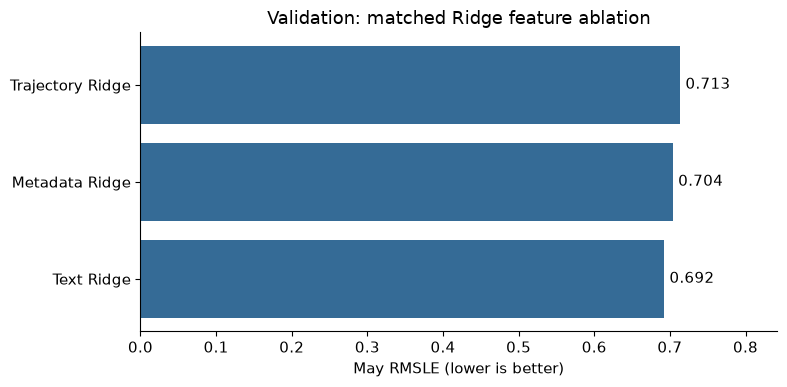

Adding text changes May RMSLE by **-0.0116** versus metadata Ridge (negative is better). This comparison is for selection, not an independent final-test claim.

In [29]:
ablation_names = ['Trajectory Ridge', 'Metadata Ridge', 'Text Ridge']
ablation = validation_scores.loc[ablation_names]
fig, ax = plt.subplots()
bars = ax.barh(ablation.index, ablation['RMSLE'], color=BLUE)
ax.bar_label(bars, fmt='%.3f', padding=4)
ax.set(xlabel='May RMSLE (lower is better)', title='Validation: matched Ridge feature ablation')
ax.set_xlim(0, ablation['RMSLE'].max() * 1.18)
ax.invert_yaxis()
fig.tight_layout()
plt.show()
text_change = ablation.loc['Text Ridge', 'RMSLE'] - ablation.loc['Metadata Ridge', 'RMSLE']
display(Markdown(f'Adding text changes May RMSLE by **{text_change:+.4f}** versus metadata Ridge '
                 '(negative is better). This comparison is for selection, not an independent final-test claim.'))

### Freeze the decision

Choose the lowest May RMSLE, including baselines. Freeze its settings, feature set, prediction floor and evaluation slices before creating test features or inspecting test label values. The final comparison is limited to the selected model, the two baselines and the one-variable Ridge; it does not select another winner on test.

In [30]:
chosen_name = validation_scores.index[0]
frozen_model = None
if chosen_name == 'Training log-mean':
    frozen_model = clone(constant_model)
elif chosen_name != 'Latest observed':
    frozen_model = clone(searches[chosen_name].best_estimator_)
decision = {'selected_model': chosen_name, 'selection_metric': 'May RMSLE',
            'validation_RMSLE': float(validation_scores.loc[chosen_name, 'RMSLE']),
            'test_start': str(TEST_START), 'label_delay': str(LABEL_DELAY),
            'archive_sha256': archive_hash,
            'selected_parameters': searches[chosen_name].best_params_ if chosen_name in searches else {}}
(RESULTS / 'frozen_decision.json').write_text(json.dumps(decision, indent=2))
print('Frozen selection:', chosen_name)
print('May RMSLE:', round(decision['validation_RMSLE'], 4))

Frozen selection: Metadata boosting
May RMSLE: 0.6909


## 7. Final held-out evaluation

Refit from scratch on mature pre-June articles, including May and the now-available pre-May gap. Preprocessing is relearned on this development set only. No model choice changes after this section.

In [31]:
X_development = make_features(development)
y_development = development['target']
final_constant = clone(constant_model)
final_simple = clone(searches['Six-hour Ridge'].best_estimator_)
with threadpool_limits(limits=2):
    final_constant.fit(X_development, y_development)
    final_simple.fit(X_development, y_development)
    if frozen_model is not None:
        frozen_model.fit(X_development, y_development)
print('Final fitting articles:', len(development))

Final fitting articles: 36772


In [32]:
X_test = make_features(test)
y_test = test['target']
test_predictions = {
    'Training log-mean': predict_nonnegative(final_constant, X_test),
    'Latest observed': np.expm1(X_test['log_latest'].to_numpy()),
    'Six-hour Ridge': predict_nonnegative(final_simple, X_test)}
if frozen_model is not None:
    with threadpool_limits(limits=2):
        test_predictions[chosen_name] = predict_nonnegative(frozen_model, X_test)
selected_prediction = test_predictions[chosen_name]
test_rows = []
for name, prediction in test_predictions.items():
    test_rows.append({'model': name, 'selected_on_May': name == chosen_name,
                      **metrics(y_test, prediction)})
test_scores = pd.DataFrame(test_rows).set_index('model')
display(test_scores.round(4))

,selected_on_May,RMSLE,MAE_shares,RMSE_shares
model,,,,
Training log-mean,False,2.0555,176.9397,658.9518
Latest observed,False,1.0984,122.9416,498.9148
Six-hour Ridge,False,0.7871,99.1195,578.6397
Metadata boosting,True,0.7371,76.8090,369.7040


### Where does the selected model miss?

All following diagnostics are descriptive test analysis. They motivate future experiments only; the frozen model is not retuned. Group rows by topic, early-history completeness and training-defined target quantiles. Report group sizes because small groups give unstable scores.

In [33]:
errors = test[['IDLink', 'PublishDate', 'Title', 'Topic']].copy()
errors['actual'] = y_test
errors['predicted'] = selected_prediction
errors['latest'] = test_predictions['Latest observed']
errors['absolute_error'] = np.abs(errors['actual'] - errors['predicted'])
errors['log_error'] = np.log1p(errors['predicted']) - np.log1p(errors['actual'])
errors['history'] = np.where(X_test['missing_fraction'].eq(0), 'complete early history', 'partial early history')
training_q90 = y_train.quantile(.90)
training_q99 = y_train.quantile(.99)
errors['target_band'] = pd.cut(errors['actual'], [-np.inf, training_q90, training_q99, np.inf],
                              labels=['up to train p90', 'train p90–p99', 'above train p99'])

def group_errors(column):
    rows = []
    for group, frame in errors.groupby(column, observed=True):
        rows.append({'group': group, 'articles': len(frame),
                      **metrics(frame['actual'], frame['predicted'])})
    return pd.DataFrame(rows).set_index('group')

display(group_errors('Topic').round(3))

,articles,RMSLE,MAE_shares,RMSE_shares
group,,,,
economy,579,0.720,22.284,82.126
microsoft,300,0.502,9.728,42.359
obama,1891,0.740,114.189,453.394
palestine,464,0.865,35.880,324.496


In [34]:
display(group_errors('history').round(3))

,articles,RMSLE,MAE_shares,RMSE_shares
group,,,,
complete early history,1422,0.766,73.989,316.610
partial early history,1812,0.714,79.022,406.543


In [35]:
display(group_errors('target_band').round(3))

,articles,RMSLE,MAE_shares,RMSE_shares
group,,,,
up to train p90,2802,0.688,18.434,37.552
train p90–p99,402,0.994,300.734,458.306
above train p99,30,1.078,2528.398,3433.353


### Topic mix shift

Compare article proportions only after opening the final test. Different topic mixes can change aggregate error without a uniform change in within-topic performance.

In [36]:
topic_mix = pd.DataFrame({'train_percent': train['Topic'].value_counts(normalize=True) * 100,
                          'test_percent': test['Topic'].value_counts(normalize=True) * 100})
display(topic_mix.round(1))

,train_percent,test_percent
Topic,,
economy,36.3,17.9
microsoft,19.9,9.3
obama,33.9,58.5
palestine,9.9,14.3


Obama-topic articles rise from about 34% of training to 58% of the test cohort. Their larger share-scale errors therefore carry more weight in the final aggregate. This is a descriptive coverage shift, not a causal explanation.

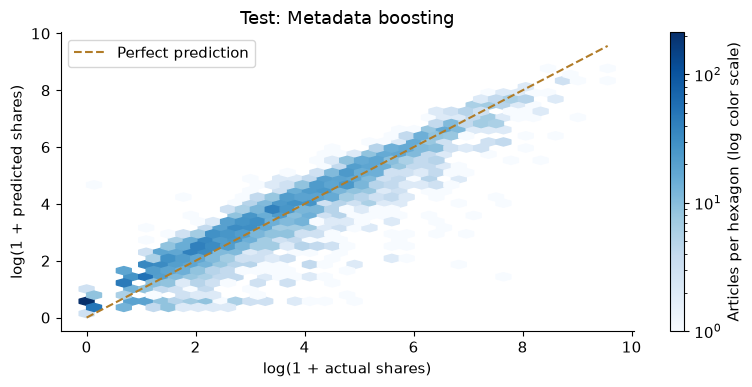

Above the training 99th-percentile threshold, the model underpredicts **96.7%** of **30** test articles. Log-loss optimization can leave large original-scale misses.

In [37]:
fig, ax = plt.subplots()
density = ax.hexbin(np.log1p(errors['actual']), np.log1p(errors['predicted']),
                    gridsize=35, mincnt=1, bins='log', cmap='Blues')
limit = float(np.log1p(errors[['actual', 'predicted']]).max().max())
ax.plot([0, limit], [0, limit], '--', color=GOLD, label='Perfect prediction')
ax.set(xlabel='log(1 + actual shares)', ylabel='log(1 + predicted shares)',
       title=f'Test: {chosen_name}')
ax.legend()
fig.colorbar(density, ax=ax, label='Articles per hexagon (log color scale)')
fig.tight_layout()
plt.show()
tail = errors.loc[errors['actual'].gt(training_q99)]
display(Markdown(f'Above the training 99th-percentile threshold, the model underpredicts '
                 f'**{tail["predicted"].lt(tail["actual"]).mean():.1%}** of **{len(tail):,}** test articles. '
                 'Log-loss optimization can leave large original-scale misses.'))

### Time stability and largest misses

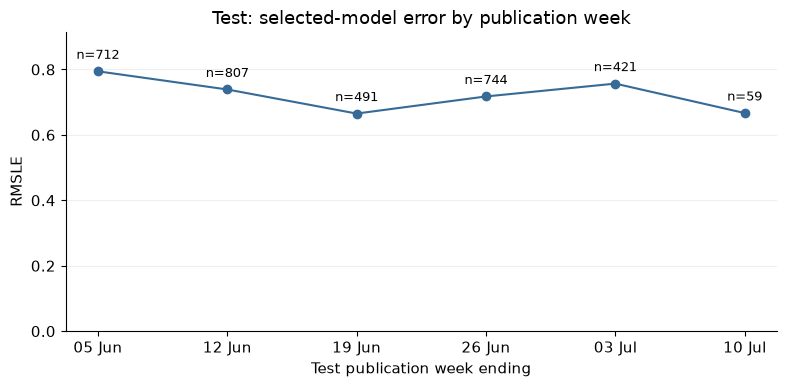

Weekly test RMSLE ranges from **0.665** to **0.794**. Labels give article counts; the last week contains only 59 articles. Edge weeks are partial, and this short history does not establish long-term stability.

In [38]:
daily_rmsle = errors.assign(squared_log_error=errors['log_error'] ** 2)
daily_rmsle = daily_rmsle.set_index('PublishDate').resample('W')['squared_log_error'].mean().pow(.5)
fig, ax = plt.subplots()
ax.plot(daily_rmsle.index, daily_rmsle, marker='o', color=BLUE)
ax.set(xlabel='Test publication week ending', ylabel='RMSLE',
       title='Test: selected-model error by publication week')
ax.set_xticks(daily_rmsle.index)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=.2)
weekly_counts = errors.set_index('PublishDate').resample('W')['IDLink'].count()
for date, value in daily_rmsle.items():
    ax.annotate(f'n={weekly_counts.loc[date]}', (date, value), xytext=(0, 9),
                textcoords='offset points', ha='center', fontsize=9)
ax.set_ylim(0, daily_rmsle.max() * 1.15)
fig.autofmt_xdate(rotation=0, ha='center')
fig.tight_layout()
plt.show()
display(Markdown(f'Weekly test RMSLE ranges from **{daily_rmsle.min():.3f}** to **{daily_rmsle.max():.3f}**. '
                 'Labels give article counts; the last week contains only 59 articles. Edge weeks are partial, '
                 'and this short history does not establish long-term stability.'))

In [39]:
largest_errors = errors.nlargest(5, 'absolute_error')[['IDLink', 'Topic', 'Title', 'actual', 'predicted', 'absolute_error']].copy()
largest_errors['Title'] = largest_errors['Title'].str.slice(0, 70)
display(largest_errors.round(1))

,IDLink,Topic,Title,actual,predicted,absolute_error
79804,101650,obama,WATCH: 8th-Grader Nails Impersonations Of Trum...,14188.0,3735.7,10452.3
81177,102407,obama,Obama is gutting Medicare,9218.0,1213.5,8004.5
79626,101578,palestine,Israel 'cuts water supply' to West Bank during...,13146.0,6427.1,6718.9
78577,100557,obama,"Sanders meets with Obama, Reid ahead of final ...",5306.0,621.5,4684.5
79945,101708,obama,America has suffered a terror attack every yea...,3973.0,244.8,3728.2


### Paired uncertainty and residual checks

Resample whole publication dates, keeping all articles on a selected day together. The percentile interval compares selected-model RMSLE minus persistence RMSLE; negative favors the selected model. This is conditional on the chosen model and observed test period. Days may still be dependent, and the interval does not include model-selection uncertainty or future distribution shifts.

In [40]:
daily_losses = pd.DataFrame({
    'day': test['PublishDate'].dt.floor('D'),
    'selected': (np.log1p(y_test) - np.log1p(selected_prediction)) ** 2,
    'persistence': (np.log1p(y_test) - np.log1p(test_predictions['Latest observed'])) ** 2,
    'articles': 1}).groupby('day').sum()
rng = np.random.default_rng(SEED)
bootstrap_differences = []
for _ in range(500):
    indices = rng.integers(0, len(daily_losses), len(daily_losses))
    sampled = daily_losses.iloc[indices].sum()
    difference = np.sqrt(sampled['selected'] / sampled['articles']) - np.sqrt(sampled['persistence'] / sampled['articles'])
    bootstrap_differences.append(difference)
interval = np.quantile(bootstrap_differences, [.025, .975])
print('Selected minus persistence RMSLE, paired day-bootstrap 95% interval:', np.round(interval, 4))
print('Predictions below latest observed level:', int((selected_prediction < errors['latest']).sum()))
print('Test zero-target fraction:', round(y_test.eq(0).mean(), 4))
print('Test unseen-source fraction:', round((~X_test['Source'].isin(X_development['Source'])).mean(), 4))

Selected minus persistence RMSLE, paired day-bootstrap 95% interval: [-0.4092 -0.3139]
Predictions below latest observed level: 2
Test zero-target fraction: 0.0863
Test unseen-source fraction: 0.0362


## 8. Conclusions and reproducibility

The result below is computed from the executed tables. Lower RMSLE need not imply lower MAE or RMSE. No claim is made about unseen topics, modern Facebook behavior, pageviews or causal effects.

In [41]:
selected_scores = test_scores.loc[chosen_name]
persistence_scores = test_scores.loc['Latest observed']
relative_gain = 1 - selected_scores['RMSLE'] / persistence_scores['RMSLE']
display(Markdown(
    f'**{chosen_name}** was selected on May validation. On **{len(test):,}** held-out articles, '
    f'it achieves **RMSLE {selected_scores["RMSLE"]:.3f}**, **MAE {selected_scores["MAE_shares"]:,.1f} shares**, '
    f'and **RMSE {selected_scores["RMSE_shares"]:,.1f} shares**. Its RMSLE reduction versus persistence is '
    f'**{relative_gain:.1%}**; the paired day-bootstrap difference interval is '
    f'**[{interval[0]:.3f}, {interval[1]:.3f}]**.'))

**Metadata boosting** was selected on May validation. On **3,234** held-out articles, it achieves **RMSLE 0.737**, **MAE 76.8 shares**, and **RMSE 369.7 shares**. Its RMSLE reduction versus persistence is **32.9%**; the paired day-bootstrap difference interval is **[-0.409, -0.314]**.

**What this exercise establishes.** Early share history is a legitimate forecasting input; text and metadata must earn their place on later validation data. The chronological gap and fitted pipelines protect different leakage routes. One-to-one joins and content deduplication protect the example unit.

**Reading the errors.** Text reduces May Ridge RMSLE, but the winning boosting score is only about 0.0013 lower than Text Ridge; that small selection margin is not strong evidence that boosting is universally better. On test, the selected model beats persistence on all three reported metrics. Viral misses remain large: 29 of 30 articles above the training 99th percentile are underpredicted. Two predictions fall below the latest observed count; we report that inconsistency without imposing a new post-test prediction rule.

**Limits.** Selection requires an observed early history and label, so missingness creates coverage bias. Exact-content removal is conservative and may discard distinct syndicated URLs; near duplicates remain. The collection spans four query topics in 2015–2016, with uneven timing and source coverage. The timestamp timezone, exact API polling times and text revisions are unavailable. Reported share snapshots may be revised in other datasets even though the retained training series show no early decreases. Viral outliers dominate share-scale errors. The final test is short; its bootstrap interval is approximate.

**Next experiments, on a new future holdout:** audit true ingestion/version timestamps, compare several rolling test periods, investigate source and topic drift, and test a count-scale objective if large viral misses matter more than proportional accuracy. Reusing this test for those choices would make it validation data.

**Interview time budget:** 60 minutes for source/join/availability checks, 45 for splits and EDA, 60 for features and baselines, 60 for pipelines and a small search, 45 for error analysis, and 30–60 for execution checks and explanation. Optional additions should wait until the complete simple workflow runs.

In [42]:
cv_results.to_csv(RESULTS / 'training_cv.csv')
validation_scores.to_csv(RESULTS / 'validation_scores.csv')
test_scores.to_csv(RESULTS / 'test_scores.csv')
errors.drop(columns=['Title']).to_csv(RESULTS / 'test_predictions.csv', index=False)
pd.DataFrame(split_rows).to_csv(RESULTS / 'split_summary.csv', index=False)
cohort_audit.to_csv(RESULTS / 'cohort_audit.csv', header=['articles'])
versions = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']:
    versions[package] = importlib.metadata.version(package)
summary = {**decision, 'training_articles': len(train), 'validation_articles': len(valid),
           'test_articles': len(test), 'final_fit_articles': len(development),
           'test_metrics': metrics(y_test, selected_prediction),
           'RMSLE_reduction_vs_persistence': float(relative_gain),
           'paired_day_bootstrap_interval': interval.tolist(),
           'runtime_seconds': round(time.perf_counter() - run_started, 1), 'versions': versions}
(RESULTS / 'run_summary.json').write_text(json.dumps(summary, indent=2))
print('Results saved in:', RESULTS)
print('Runtime, seconds:', summary['runtime_seconds'])
display(pd.Series(versions, name='version').to_frame())

Results saved in: results
Runtime, seconds: 22.7


,version
python,3.12.14
numpy,2.5.2
pandas,3.0.5
scipy,1.18.0
scikit-learn,1.9.0
matplotlib,3.11.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0


Dataset attribution: Torgo, L. & Moniz, N. (2018), *News Popularity in Multiple Social Media Platforms*, UCI Machine Learning Repository, [doi:10.24432/C5H029](https://doi.org/10.24432/C5H029), CC BY 4.0. Companion paper: Moniz, N. & Torgo, L. (2018), *Multi-Source Social Feedback of Online News Feeds*, [arXiv:1801.07055](https://arxiv.org/abs/1801.07055).

Implementation references: [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [ColumnTransformer and Pipeline](https://scikit-learn.org/stable/modules/compose.html), [target transformation](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html). Source documentation was checked on 25 October 2026.